In [1]:
!unzip fine_tuning.zip

Archive:  fine_tuning.zip
   creating: fine_tuning/
  inflating: fine_tuning/bert_fine_tuning_peft.py  
   creating: fine_tuning/best_params/
  inflating: fine_tuning/best_params/p-indobertweet.json  
  inflating: fine_tuning/best_params/p-mbert.json  
  inflating: fine_tuning/best_params/p-xlm-r-base.json  
  inflating: fine_tuning/best_params/p-xlm-r-large.json  
   creating: fine_tuning/dataset/
   creating: fine_tuning/dataset/.ipynb_checkpoints/
  inflating: fine_tuning/dataset/all_data.csv  
  inflating: fine_tuning/dataset/test.csv  
  inflating: fine_tuning/dataset/train.csv  
  inflating: fine_tuning/dataset/train_augmented.csv  
  inflating: fine_tuning/dataset/val.csv  
  inflating: fine_tuning/requirements.txt  


In [2]:
%cd fine_tuning

/content/fine_tuning


In [3]:
!pip install -r requirements.txt

  Cloning https://github.com/huggingface/peft (to revision cf04d0353f0343cbf66627228c4495f51669af34) to /tmp/pip-install-3fst093q/peft_d8fbe295b28a4a2a961472d75d297cf4
  Running command git clone --filter=blob:none --quiet https://github.com/huggingface/peft /tmp/pip-install-3fst093q/peft_d8fbe295b28a4a2a961472d75d297cf4
  Running command git rev-parse -q --verify 'cf04d0353f0343cbf66627228c4495f51669af34^{commit}'
  cf04d0353f0343cbf66627228c4495f51669af34
  Running command git checkout -q cf04d0353f0343cbf66627228c4495f51669af34
  Resolved https://github.com/huggingface/peft to commit cf04d0353f0343cbf66627228c4495f51669af34
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 98.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━

In [4]:
import pandas as pd
import numpy as np
import os
import torch
import time
import json

from peft import LoraConfig, LoraModel, get_peft_model, TaskType
from datasets import Dataset
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
)

os.environ["TOKENIZERS_PARALLELISM"] = "false"
use_cuda = torch.cuda.is_available()

In [5]:
df = pd.read_csv('dataset/all_data.csv')
train_data = pd.read_csv('dataset/train_augmented.csv')
train_data['label'] = train_data['label'].str.capitalize()
val_data = pd.read_csv('dataset/val.csv')
test_data = pd.read_csv('dataset/test.csv')

# Length train, val, and test
print("Train: ",len(train_data))
print("Val: ",len(val_data))
print("Test: ",len(test_data))

Train:  8202
Val:  1062
Test:  1062


In [6]:
tags = np.unique(df['label'])
num_labels = len(tags)
max_length = 128
label2id = {t: i for i, t in enumerate(tags)}
id2label = {i: t for i, t in enumerate(tags)}

In [7]:
def model_init(model_name):
    global tokenizer
    global data_collator
    global tr_model

    base_model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=num_labels,
        id2label=id2label,
        label2id=label2id
    )
    tokenizer = AutoTokenizer.from_pretrained(model_name, model_max_length=128)

    # Configure LoRA
    lora_config = LoraConfig(
        task_type=TaskType.SEQ_CLS,
        r=8, # Rank of the low-rank matrices
        lora_alpha=32,
        lora_dropout=0.1
    )

    # Wrap the base model with the LoRA configuration
    model = get_peft_model(base_model, lora_config)
    model.print_trainable_parameters()

    return model, tokenizer


def tokenize_function(examples):
    # process the input sequence
    tokenized_input = tokenizer(examples["tweet"],
                                truncation=True,
                                padding='max_length',
                                max_length=max_length)
    # process the labels
    tokenized_input['label'] = [label2id[lb] for lb in examples['label']]

    return tokenized_input


def preprocessing():
    X_train = Dataset.from_pandas(train_data)
    X_val = Dataset.from_pandas(val_data)
    X_test = Dataset.from_pandas(test_data)

    tokenized_train_data = X_train.map(tokenize_function, batched=True)
    tokenized_val_data = X_val.map(tokenize_function, batched=True)
    tokenized_test_data = X_test.map(tokenize_function, batched=True)

    return tokenized_train_data, tokenized_val_data, tokenized_test_data


def compute_metrics(p):
    pred, labels = p
    pred = np.argmax(pred, axis=1)

    true_labels = [tags[l] for l in labels]
    true_predictions = [tags[pr] for pr in pred]

    report = classification_report(true_labels, true_predictions, digits=4)
    acc = accuracy_score(y_true=true_labels, y_pred=true_predictions)
    rec = recall_score(y_true=true_labels, y_pred=true_predictions, average="macro")
    prec = precision_score(y_true=true_labels, y_pred=true_predictions, average="macro")
    f1 = f1_score(y_true=true_labels, y_pred=true_predictions, average="macro", zero_division=1.0)

    print("Classification Report:\n{}".format(report))
    return {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}

In [8]:
# to generate the confusion matrix

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

def generate_confusion_matrix(true_labels, pred_labels, num_labels):
    cm = confusion_matrix(true_labels, pred_labels)
    labels = [id2label[i] for i in range(num_labels)]
    plt.figure(figsize=(8, 6))
    sns.set(font_scale=1.5)
    sns.heatmap(cm,
                annot=True,
                fmt="d",
                cmap="Blues",
                xticklabels=labels,
                yticklabels=labels)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.yticks(rotation=0)
    plt.show()

In [9]:
def train_model(model_name, output_dir, learning_rate, train_batch_size, eval_batch_size, num_epochs, weight_decay):

    model, tokenizer = model_init(model_name)
    train_tokenized, val_tokenized, test_tokenized = preprocessing()

    training_args = TrainingArguments(
        output_dir=output_dir,
        logging_strategy="epoch",
        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit = 1,
        learning_rate=learning_rate,
        num_train_epochs=num_epochs,
        per_device_train_batch_size=train_batch_size,
        per_device_eval_batch_size=eval_batch_size,
        weight_decay=weight_decay,
        load_best_model_at_end=True,
        #push_to_hub=True, # to push to hub during the training
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_tokenized,
        eval_dataset=val_tokenized,
        processing_class=tokenizer,
        compute_metrics=compute_metrics,
    )

    trainer.train()
    trainer.save_model(output_dir)
    #trainer.push_to_hub(commit_message="Training complete")

    # Get the evaluation results
    trainer.eval_dataset=test_tokenized
    evaluation_results = trainer.evaluate()
    print(evaluation_results)

    # make prediction on the test set
    predictions = trainer.predict(test_tokenized)
    pred_labels = np.argmax(predictions.predictions, axis=1)
    true_labels = test_tokenized["label"]

    # Generate confusion matrix
    generate_confusion_matrix(true_labels, pred_labels, num_labels)

    return trainer

In [10]:

def show_log_history(trainer):
    log_history = pd.DataFrame(trainer.state.log_history)
    log_history = log_history.fillna(0)
    log_history = log_history.groupby(["epoch"]).sum()

    log_history[["loss", "eval_loss"]].plot()
    plt.show()

In [11]:
def main(model_name, output_dir, best_params):
    start = time.time()
     # load json file containing best params
    best_params = best_params

    with open(best_params, 'r') as js:
        data = json.load(js)

    print(data)

    # define best params
    num_train_epochs = data['num_train_epochs']
    learning_rate = data['learning_rate']
    train_batch_size = data['per_device_train_batch_size']
    eval_batch_size = data['per_device_eval_batch_size']
    weight_decay = data['weight_decay']

    # training
    tr_model = train_model(model_name=model_name,
                           output_dir=output_dir,
                           learning_rate=learning_rate,
                           train_batch_size=train_batch_size,
                           eval_batch_size=eval_batch_size,
                           num_epochs=num_train_epochs,
                           weight_decay=weight_decay)

    print('Training finished!')

    show_log_history(tr_model)


    end = time.time()
    exec_time = (end - start) / 60
    print(f'Total time: {exec_time} minutes')

{'num_train_epochs': 10, 'learning_rate': 0.0003, 'per_device_train_batch_size': 8, 'per_device_eval_batch_size': 64, 'weight_decay': 0.014392444763150837}


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/445M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indolem/indobertweet-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

... (10 outputs left out)

wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 21523190 (21523190-universitas-islam-indonesia) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.928900,0.737631,0.739171,0.741948,0.784358,0.745408
2,0.677400,0.670972,0.766478,0.776448,0.773919,0.773704
3,0.602200,0.716449,0.762712,0.760897,0.791531,0.770818
4,0.533900,0.761220,0.762712,0.767522,0.773363,0.769249
5,0.470900,0.804473,0.750471,0.751525,0.772729,0.758027
6,0.406800,0.860485,0.764595,0.767728,0.780008,0.773331
7,0.376500,0.897127,0.770245,0.772377,0.786289,0.777466
8,0.333500,0.968788,0.765537,0.767272,0.780531,0.772693
9,0.289700,1.014806,0.767420,0.769977,0.781849,0.774388
10,0.278500,1.030394,0.762712,0.765170,0.776780,0.769518


Classification Report:
              precision    recall  f1-score   support

       Anger     0.7431    0.8950    0.8120       181
        Fear     0.7892    0.8792    0.8317       149
         Joy     0.7344    0.7921    0.7622       178
        Love     0.6494    0.8547    0.7380       117
     Neutral     0.8531    0.4251    0.5674       287
         Sad     0.6825    0.8600    0.7611       150

    accuracy                         0.7392      1062
   macro avg     0.7419    0.7844    0.7454      1062
weighted avg     0.7590    0.7392    0.7250      1062

Classification Report:
              precision    recall  f1-score   support

       Anger     0.8471    0.7348    0.7870       181
        Fear     0.8354    0.8859    0.8599       149
         Joy     0.8000    0.7191    0.7574       178
        Love     0.7381    0.7949    0.7654       117
     Neutral     0.6961    0.7422    0.7184       287
         Sad     0.7419    0.7667    0.7541       150

    accuracy                   

Classification Report:
              precision    recall  f1-score   support

       Anger     0.8650    0.7790    0.8198       181
        Fear     0.7610    0.9030    0.8259       134
         Joy     0.8358    0.8077    0.8215       208
        Love     0.6842    0.7647    0.7222       102
     Neutral     0.7423    0.6796    0.7096       284
         Sad     0.7455    0.8039    0.7736       153

    accuracy                         0.7759      1062
   macro avg     0.7723    0.7896    0.7788      1062
weighted avg     0.7788    0.7759    0.7754      1062

{'eval_loss': 0.6133294701576233, 'eval_accuracy': 0.775894538606403, 'eval_precision': 0.7723051039592028, 'eval_recall': 0.7896479704916962, 'eval_f1': 0.7787646420409858, 'eval_runtime': 1.9248, 'eval_samples_per_second': 551.732, 'eval_steps_per_second': 8.832, 'epoch': 10.0}
Classification Report:
              precision    recall  f1-score   support

       Anger     0.8650    0.7790    0.8198       181
        Fear     0.76

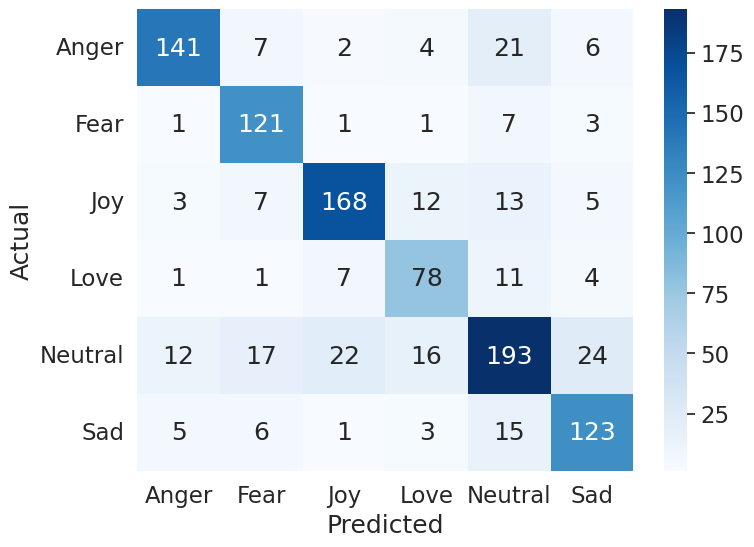

Training finished!


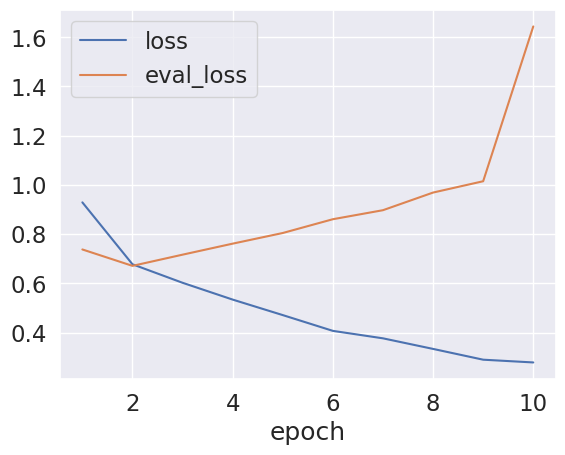

Total time: 8.237879776954651 minutes


In [12]:
#1 IndoBERTweet peft

main(
    model_name = 'indolem/indobertweet-base-uncased',
    output_dir = 'p-emotcls-indobertweet-base',
    best_params = 'best_params/p-indobertweet.json'
)

{'num_train_epochs': 10, 'learning_rate': 0.0001, 'per_device_train_batch_size': 8, 'per_device_eval_batch_size': 32, 'weight_decay': 0.0025641862948166173}


config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.24G [00:00<?, ?B/s]

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/xlm-roberta-large and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

... (4 outputs left out)

Map:   0%|          | 0/1062 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,1.155500,0.918868,0.709981,0.717625,0.760169,0.716176
2,0.798400,0.735655,0.739171,0.739972,0.757668,0.746914
3,0.723200,0.803715,0.746704,0.747202,0.782367,0.753452
4,0.670500,0.769273,0.749529,0.748288,0.764653,0.753919
5,0.622800,0.732169,0.762712,0.763012,0.781604,0.768789
6,0.580100,0.809514,0.738230,0.735177,0.767656,0.744132
7,0.545400,0.786363,0.755179,0.754709,0.773597,0.761005
8,0.533700,0.799830,0.753296,0.750157,0.774466,0.758830
9,0.497200,0.822198,0.754237,0.751549,0.776034,0.759736
10,0.471000,0.810730,0.752354,0.749369,0.773601,0.758324


Classification Report:
              precision    recall  f1-score   support

       Anger     0.7085    0.8729    0.7822       181
        Fear     0.7811    0.8859    0.8302       149
         Joy     0.6557    0.7809    0.7128       178
        Love     0.6218    0.8291    0.7106       117
     Neutral     0.8443    0.3589    0.5037       287
         Sad     0.6944    0.8333    0.7576       150

    accuracy                         0.7100      1062
   macro avg     0.7176    0.7602    0.7162      1062
weighted avg     0.7350    0.7100    0.6907      1062

Classification Report:
              precision    recall  f1-score   support

       Anger     0.7964    0.7348    0.7644       181
        Fear     0.7888    0.8523    0.8194       149
         Joy     0.7391    0.7640    0.7514       178
        Love     0.6500    0.7778    0.7082       117
     Neutral     0.7075    0.6237    0.6630       287
         Sad     0.7580    0.7933    0.7752       150

    accuracy                   

Classification Report:
              precision    recall  f1-score   support

       Anger     0.8010    0.8674    0.8329       181
        Fear     0.7261    0.8507    0.7835       134
         Joy     0.8722    0.7548    0.8093       208
        Love     0.6350    0.8529    0.7280       102
     Neutral     0.8000    0.6620    0.7245       284
         Sad     0.8089    0.8301    0.8194       153

    accuracy                         0.7815      1062
   macro avg     0.7739    0.8030    0.7829      1062
weighted avg     0.7904    0.7815    0.7810      1062

{'eval_loss': 0.66033536195755, 'eval_accuracy': 0.7815442561205274, 'eval_precision': 0.7738851623116018, 'eval_recall': 0.8029892738025272, 'eval_f1': 0.7829221997044623, 'eval_runtime': 5.6802, 'eval_samples_per_second': 186.966, 'eval_steps_per_second': 5.986, 'epoch': 10.0}
Classification Report:
              precision    recall  f1-score   support

       Anger     0.8010    0.8674    0.8329       181
        Fear     0.726

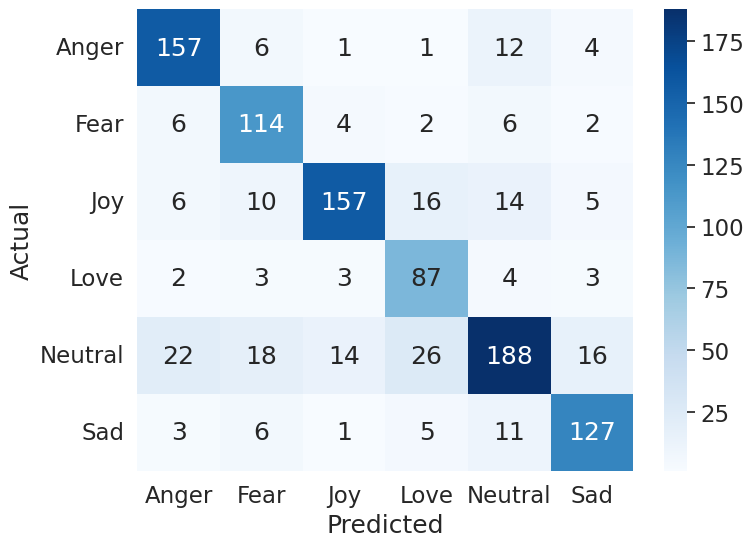

Training finished!


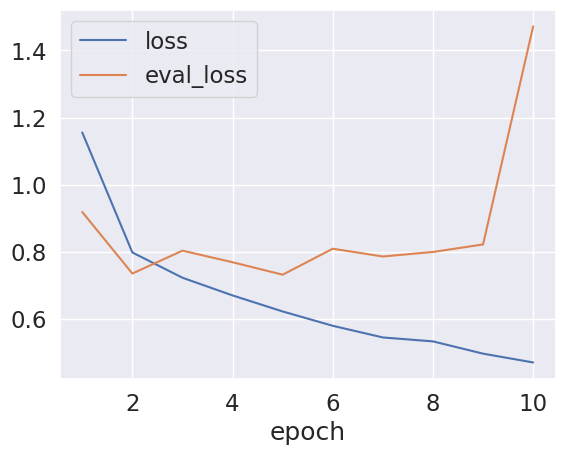

Total time: 20.60181252161662 minutes


In [13]:
#2 FacebookAI/xlm-roberta-large peft

main(
    model_name = 'FacebookAI/xlm-roberta-large',
    output_dir = 'p-emotcls-xlm-r-large',
    best_params = 'best_params/p-xlm-r-large.json'
)

{'num_train_epochs': 7, 'learning_rate': 0.0003, 'per_device_train_batch_size': 16, 'per_device_eval_batch_size': 8, 'weight_decay': 0.04306660769788212}


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

... (4 outputs left out)

Map:   0%|          | 0/1062 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,1.201300,1.171829,0.637476,0.672604,0.710677,0.636130
2,0.898800,0.804838,0.716573,0.717014,0.749077,0.724680
3,0.789800,0.754077,0.722222,0.723522,0.750614,0.731743
4,0.723300,0.863292,0.712806,0.716720,0.751700,0.719979
5,0.660600,0.756215,0.742938,0.741382,0.765046,0.749292
6,0.624000,0.796425,0.731638,0.730285,0.755359,0.738300
7,0.592700,0.793054,0.735405,0.733037,0.760728,0.742406


Classification Report:
              precision    recall  f1-score   support

       Anger     0.6897    0.7735    0.7292       181
        Fear     0.7228    0.8926    0.7988       149
         Joy     0.6188    0.7022    0.6579       178
        Love     0.5095    0.9145    0.6544       117
     Neutral     0.9123    0.1812    0.3023       287
         Sad     0.5825    0.8000    0.6742       150

    accuracy                         0.6375      1062
   macro avg     0.6726    0.7107    0.6361      1062
weighted avg     0.7076    0.6375    0.5956      1062

Classification Report:
              precision    recall  f1-score   support

       Anger     0.7697    0.7569    0.7632       181
        Fear     0.7544    0.8658    0.8063       149
         Joy     0.7707    0.6798    0.7224       178
        Love     0.6382    0.8291    0.7212       117
     Neutral     0.7379    0.5296    0.6166       287
         Sad     0.6313    0.8333    0.7184       150

    accuracy                   

Classification Report:
              precision    recall  f1-score   support

       Anger     0.7350    0.8122    0.7717       181
        Fear     0.7208    0.8284    0.7708       134
         Joy     0.8150    0.7837    0.7990       208
        Love     0.6122    0.8824    0.7229       102
     Neutral     0.8049    0.5810    0.6748       284
         Sad     0.7628    0.7778    0.7702       153

    accuracy                         0.7486      1062
   macro avg     0.7418    0.7775    0.7516      1062
weighted avg     0.7598    0.7486    0.7461      1062

{'eval_loss': 0.6966503262519836, 'eval_accuracy': 0.748587570621469, 'eval_precision': 0.7417871133899009, 'eval_recall': 0.7775472309481454, 'eval_f1': 0.7515785356220528, 'eval_runtime': 2.3827, 'eval_samples_per_second': 445.714, 'eval_steps_per_second': 55.819, 'epoch': 7.0}
Classification Report:
              precision    recall  f1-score   support

       Anger     0.7350    0.8122    0.7717       181
        Fear     0.72

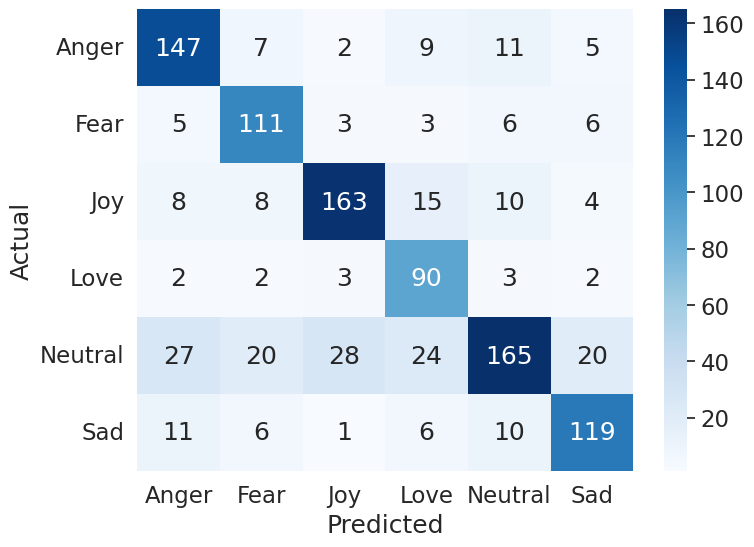

Training finished!


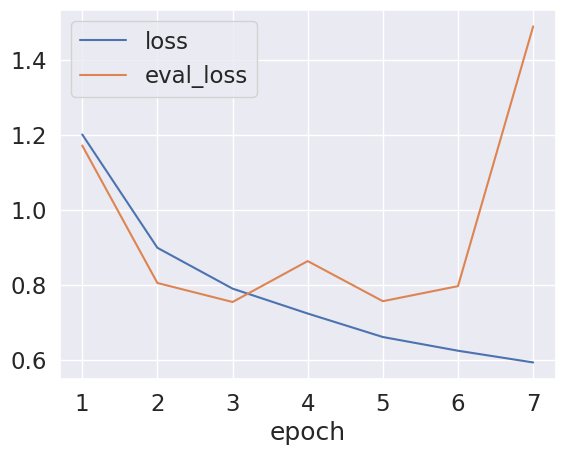

Total time: 4.60784862836202 minutes


In [14]:
#3 FacebookAI/xlm-roberta-base peft

main(
    model_name = 'FacebookAI/xlm-roberta-base',
    output_dir = 'p-emotcls-xlm-r-base',
    best_params = 'best_params/p-xlm-r-base.json'
)

{'num_train_epochs': 10, 'learning_rate': 0.0001, 'per_device_train_batch_size': 16, 'per_device_eval_batch_size': 8, 'weight_decay': 0.022795709542181866}


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

... (4 outputs left out)

Map:   0%|          | 0/1062 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,1.622600,1.440483,0.446328,0.434867,0.473079,0.433542
2,1.337600,1.199135,0.572505,0.576264,0.600112,0.578858
3,1.162800,1.096237,0.601695,0.608133,0.626645,0.611871
4,1.070100,1.084047,0.626177,0.627936,0.659073,0.636188
5,1.012300,1.010424,0.654426,0.663241,0.674875,0.665870
6,0.963200,1.014845,0.657250,0.658519,0.687228,0.667352
7,0.920400,0.980871,0.677024,0.684903,0.699838,0.688873
8,0.893700,0.990363,0.668550,0.672551,0.697809,0.679814
9,0.871300,0.984406,0.677966,0.683705,0.703193,0.688647
10,0.856200,0.976538,0.675141,0.680675,0.701366,0.687497


Classification Report:
              precision    recall  f1-score   support

       Anger     0.3484    0.2983    0.3214       181
        Fear     0.3684    0.5168    0.4302       149
         Joy     0.6340    0.5449    0.5861       178
        Love     0.4496    0.9145    0.6028       117
     Neutral     0.5112    0.3972    0.4471       287
         Sad     0.2976    0.1667    0.2137       150

    accuracy                         0.4463      1062
   macro avg     0.4349    0.4731    0.4335      1062
weighted avg     0.4470    0.4463    0.4308      1062

Classification Report:
              precision    recall  f1-score   support

       Anger     0.4459    0.3646    0.4012       181
        Fear     0.6131    0.5638    0.5874       149
         Joy     0.7192    0.5899    0.6481       178
        Love     0.5538    0.8803    0.6799       117
     Neutral     0.5573    0.5087    0.5319       287
         Sad     0.5683    0.6933    0.6246       150

    accuracy                   

Classification Report:
              precision    recall  f1-score   support

       Anger     0.6630    0.6630    0.6630       181
        Fear     0.6867    0.8507    0.7600       134
         Joy     0.8182    0.7356    0.7747       208
        Love     0.6127    0.8529    0.7131       102
     Neutral     0.6547    0.5141    0.5759       284
         Sad     0.6503    0.6928    0.6709       153

    accuracy                         0.6836      1062
   macro avg     0.6809    0.7182    0.6929      1062
weighted avg     0.6875    0.6836    0.6798      1062

{'eval_loss': 0.9615951180458069, 'eval_accuracy': 0.6836158192090396, 'eval_precision': 0.680933926088608, 'eval_recall': 0.7181904596961978, 'eval_f1': 0.6929341138991801, 'eval_runtime': 2.4611, 'eval_samples_per_second': 431.514, 'eval_steps_per_second': 54.041, 'epoch': 10.0}
Classification Report:
              precision    recall  f1-score   support

       Anger     0.6630    0.6630    0.6630       181
        Fear     0.6

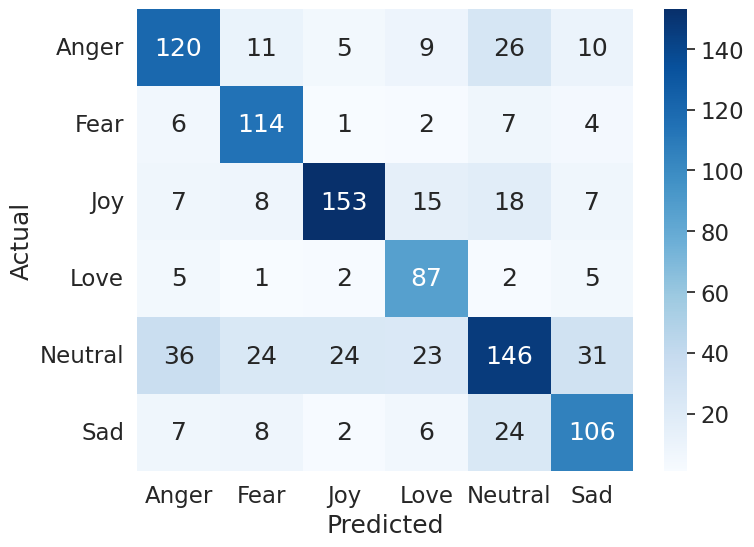

Training finished!


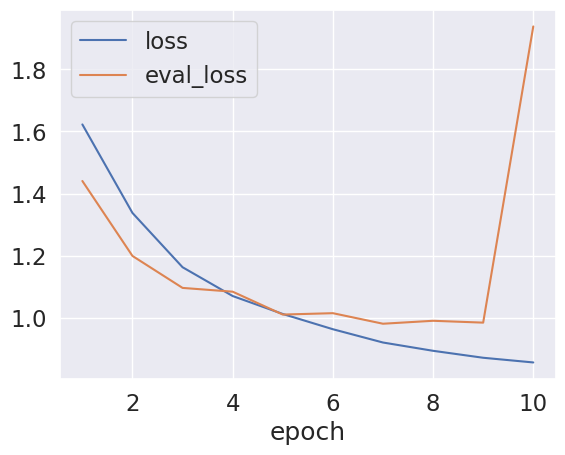

Total time: 6.5108273267745975 minutes


In [15]:
#4 google-bert/bert-base-multilingual-cased peft

main(
    model_name = 'google-bert/bert-base-multilingual-cased',
    output_dir = 'p-emotcls-bert-base',
    best_params = 'best_params/p-mbert.json'
)

In [16]:
%cd ..

[Errno 2] No such file or directory: 'content/'
/content/fine_tuning


In [17]:
!zip -r fine_tuning.zip fine_tuning/

  adding: content/fine_tuning/ (stored 0%)
  adding: content/fine_tuning/dataset/ (stored 0%)
  adding: content/fine_tuning/dataset/all_data.csv (deflated 60%)
  adding: content/fine_tuning/dataset/train.csv (deflated 57%)
  adding: content/fine_tuning/dataset/.ipynb_checkpoints/ (stored 0%)
  adding: content/fine_tuning/dataset/val.csv (deflated 56%)
  adding: content/fine_tuning/dataset/train_augmented.csv (deflated 60%)
  adding: content/fine_tuning/dataset/test.csv (deflated 57%)
  adding: content/fine_tuning/p-emotcls-indobertweet-base/ (stored 0%)
  adding: content/fine_tuning/p-emotcls-indobertweet-base/checkpoint-2052/ (stored 0%)
  adding: content/fine_tuning/p-emotcls-indobertweet-base/checkpoint-2052/adapter_config.json (deflated 50%)
  adding: content/fine_tuning/p-emotcls-indobertweet-base/checkpoint-2052/tokenizer_config.json (deflated 75%)
  adding: content/fine_tuning/p-emotcls-indobertweet-base/checkpoint-2052/optimizer.pt (deflated 8%)
  adding: content/fine_tuning/p-

In [18]:
from google.colab import files
files.download('fine_tuning.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>